In [1]:
import os
import warnings
warnings.filterwarnings("ignore")
import scanpy as sc
import anndata as ad
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
in_dir = "../../results/02_10x_visium/05_integrate_data"
out_dir = "../../results/02_10x_visium/06_integrate_data"
os.makedirs(out_dir, exist_ok=True)

In [3]:
adata = ad.read_h5ad(f"{in_dir}/adata.h5ad")

In [4]:
adata

AnnData object with n_obs × n_vars = 19740 × 18085
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'group'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'

In [5]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")

In [6]:
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], inplace=True)

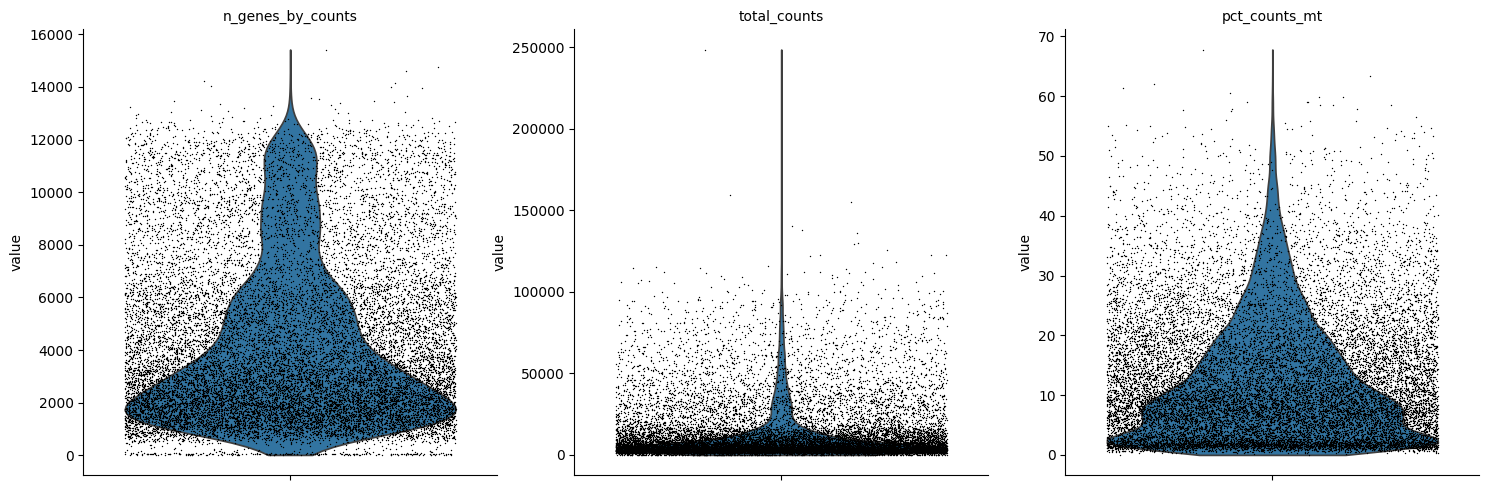

In [7]:
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
)

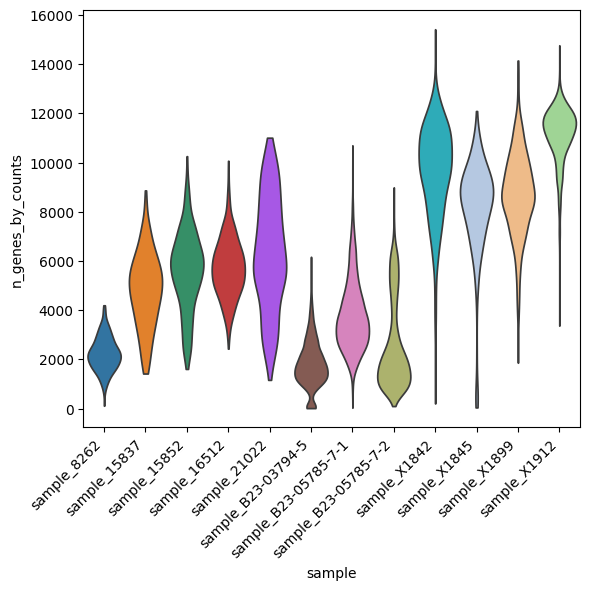

In [8]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6))
sc.pl.violin(
    adata,
    ["n_genes_by_counts"],
    groupby="sample",
    jitter=0.4, size=0, ax=ax, show=False)

ax.set_xticklabels(ax.get_xticklabels(), rotation=45, horizontalalignment='right')
plt.tight_layout()

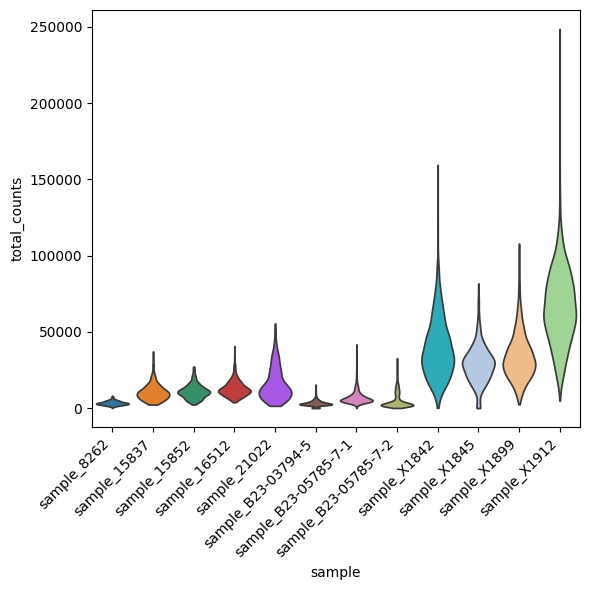

In [9]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6))
sc.pl.violin(
    adata,
    ["total_counts"],
    groupby="sample",
    jitter=0.4, size=0, ax=ax, show=False)

ax.set_xticklabels(ax.get_xticklabels(), rotation=45, horizontalalignment='right')
plt.tight_layout()

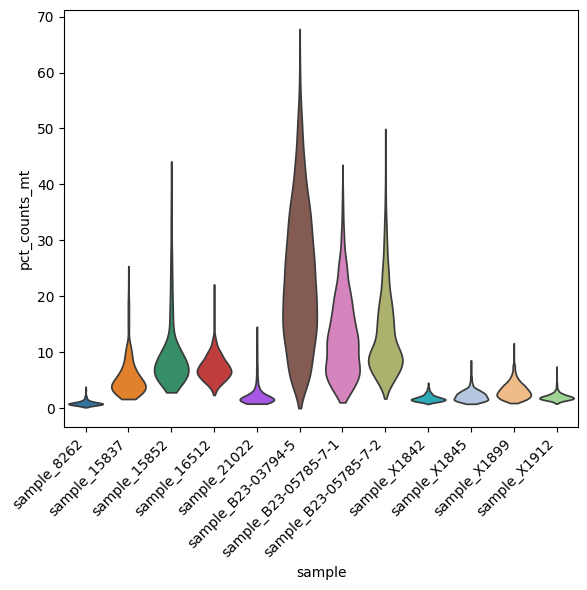

In [10]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6))
sc.pl.violin(
    adata,
    ["pct_counts_mt"],
    groupby="sample",
    jitter=0.4, size=0, ax=ax, show=False)

ax.set_xticklabels(ax.get_xticklabels(), rotation=45, horizontalalignment='right')
plt.tight_layout()

In [11]:
adata.layers["counts"] = adata.X.copy()

In [12]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

In [13]:
sc.tl.pca(adata)

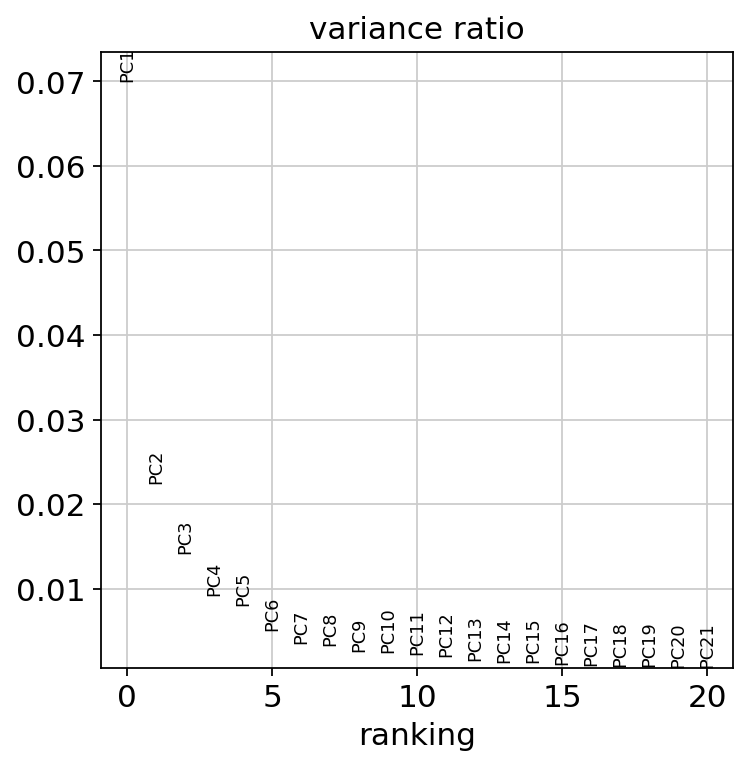

In [14]:
sc.set_figure_params(figsize=(5, 5))

sc.pl.pca_variance_ratio(adata, n_pcs=20, log=False)

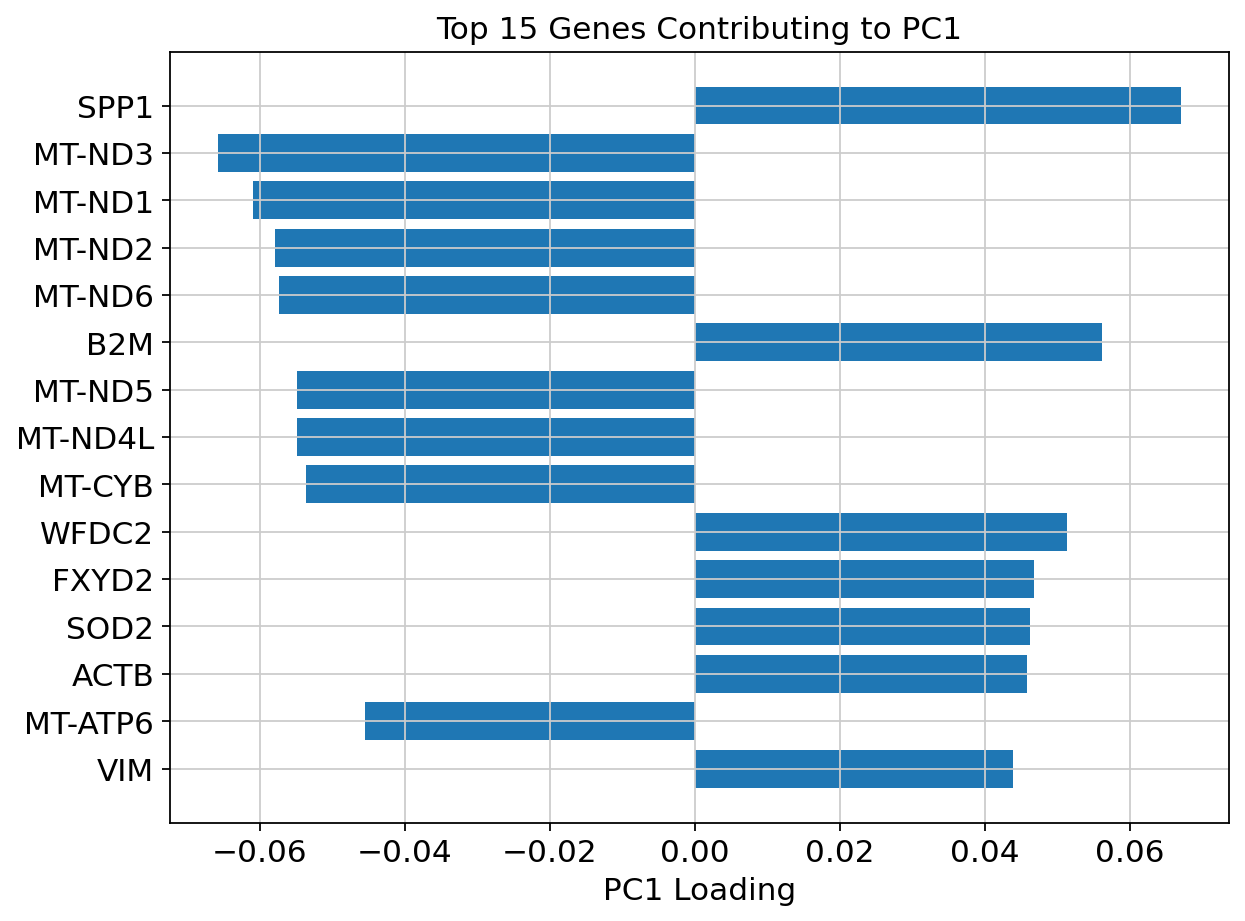

In [15]:
# Get top 10 genes for PC1
pc1 = adata.varm["PCs"][:, 0]
top_indices = np.argsort(np.abs(pc1))[::-1][:15]
top_genes = adata.var_names[top_indices]
top_values = pc1[top_indices]

# Plot
plt.figure(figsize=(8, 6))
plt.barh(top_genes[::-1], top_values[::-1])
plt.xlabel("PC1 Loading")
plt.title("Top 15 Genes Contributing to PC1")
plt.tight_layout()
plt.grid(True)
plt.show()

In [16]:
# remove MT genes and rerun PCA
adata = adata[:, ~adata.var["mt"]].copy()

In [17]:
adata.X = adata.layers["counts"].copy()

In [18]:
adata

AnnData object with n_obs × n_vars = 19740 × 18074
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'group', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'mt'
    uns: 'sample_colors', 'log1p', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: 'counts'

In [19]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

In [20]:
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)

In [21]:
sc.tl.pca(adata)

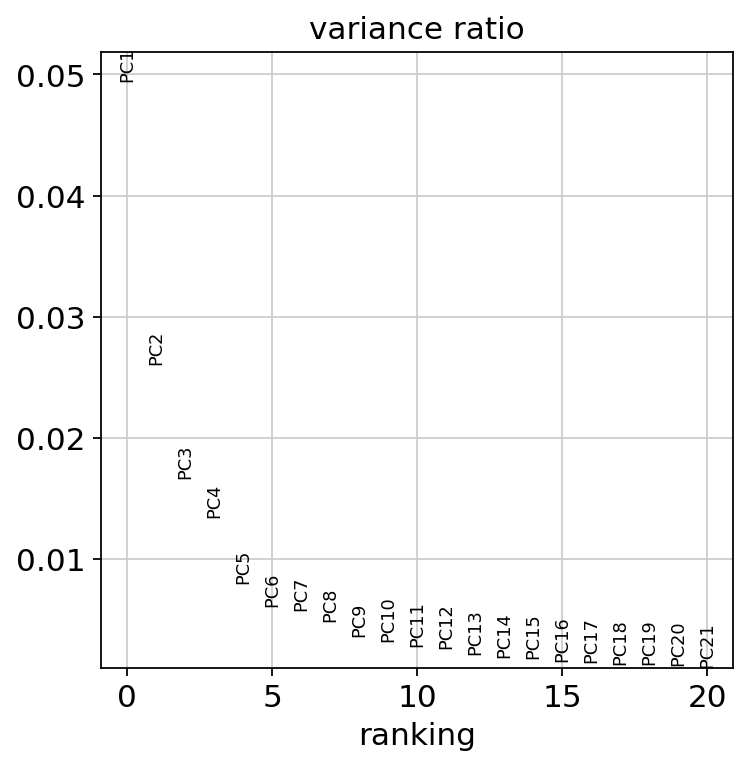

In [22]:
sc.set_figure_params(figsize=(5, 5))

sc.pl.pca_variance_ratio(adata, n_pcs=20, log=False)

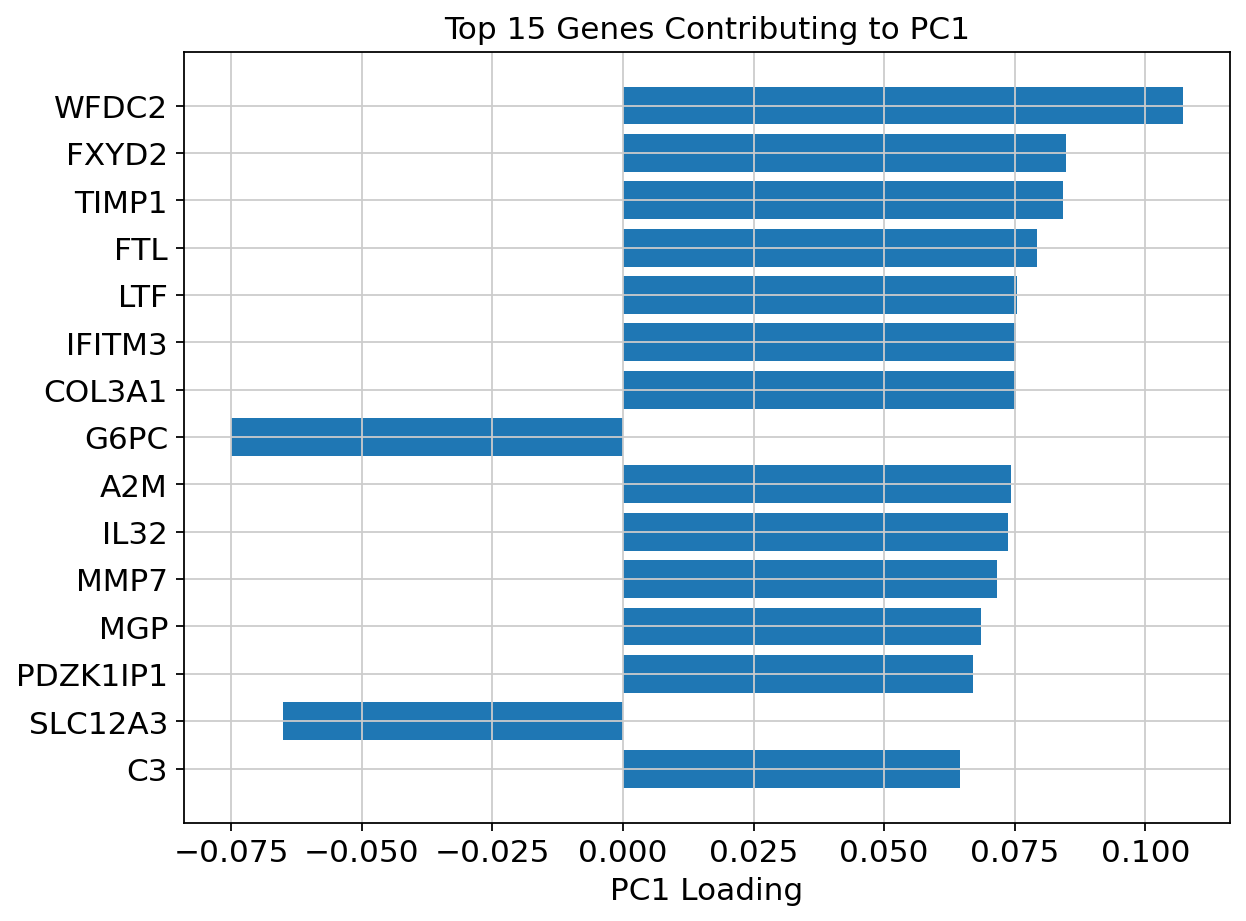

In [23]:
# Get top 15 genes for PC1
pc1 = adata.varm["PCs"][:, 0]
top_indices = np.argsort(np.abs(pc1))[::-1][:15]
top_genes = adata.var_names[top_indices]
top_values = pc1[top_indices]

# Plot
plt.figure(figsize=(8, 6))
plt.barh(top_genes[::-1], top_values[::-1])
plt.xlabel("PC1 Loading")
plt.title("Top 15 Genes Contributing to PC1")
plt.tight_layout()
plt.grid(True)
plt.show()

In [24]:
sc.pp.neighbors(adata, n_neighbors=10, n_pcs=10)
sc.tl.umap(adata)

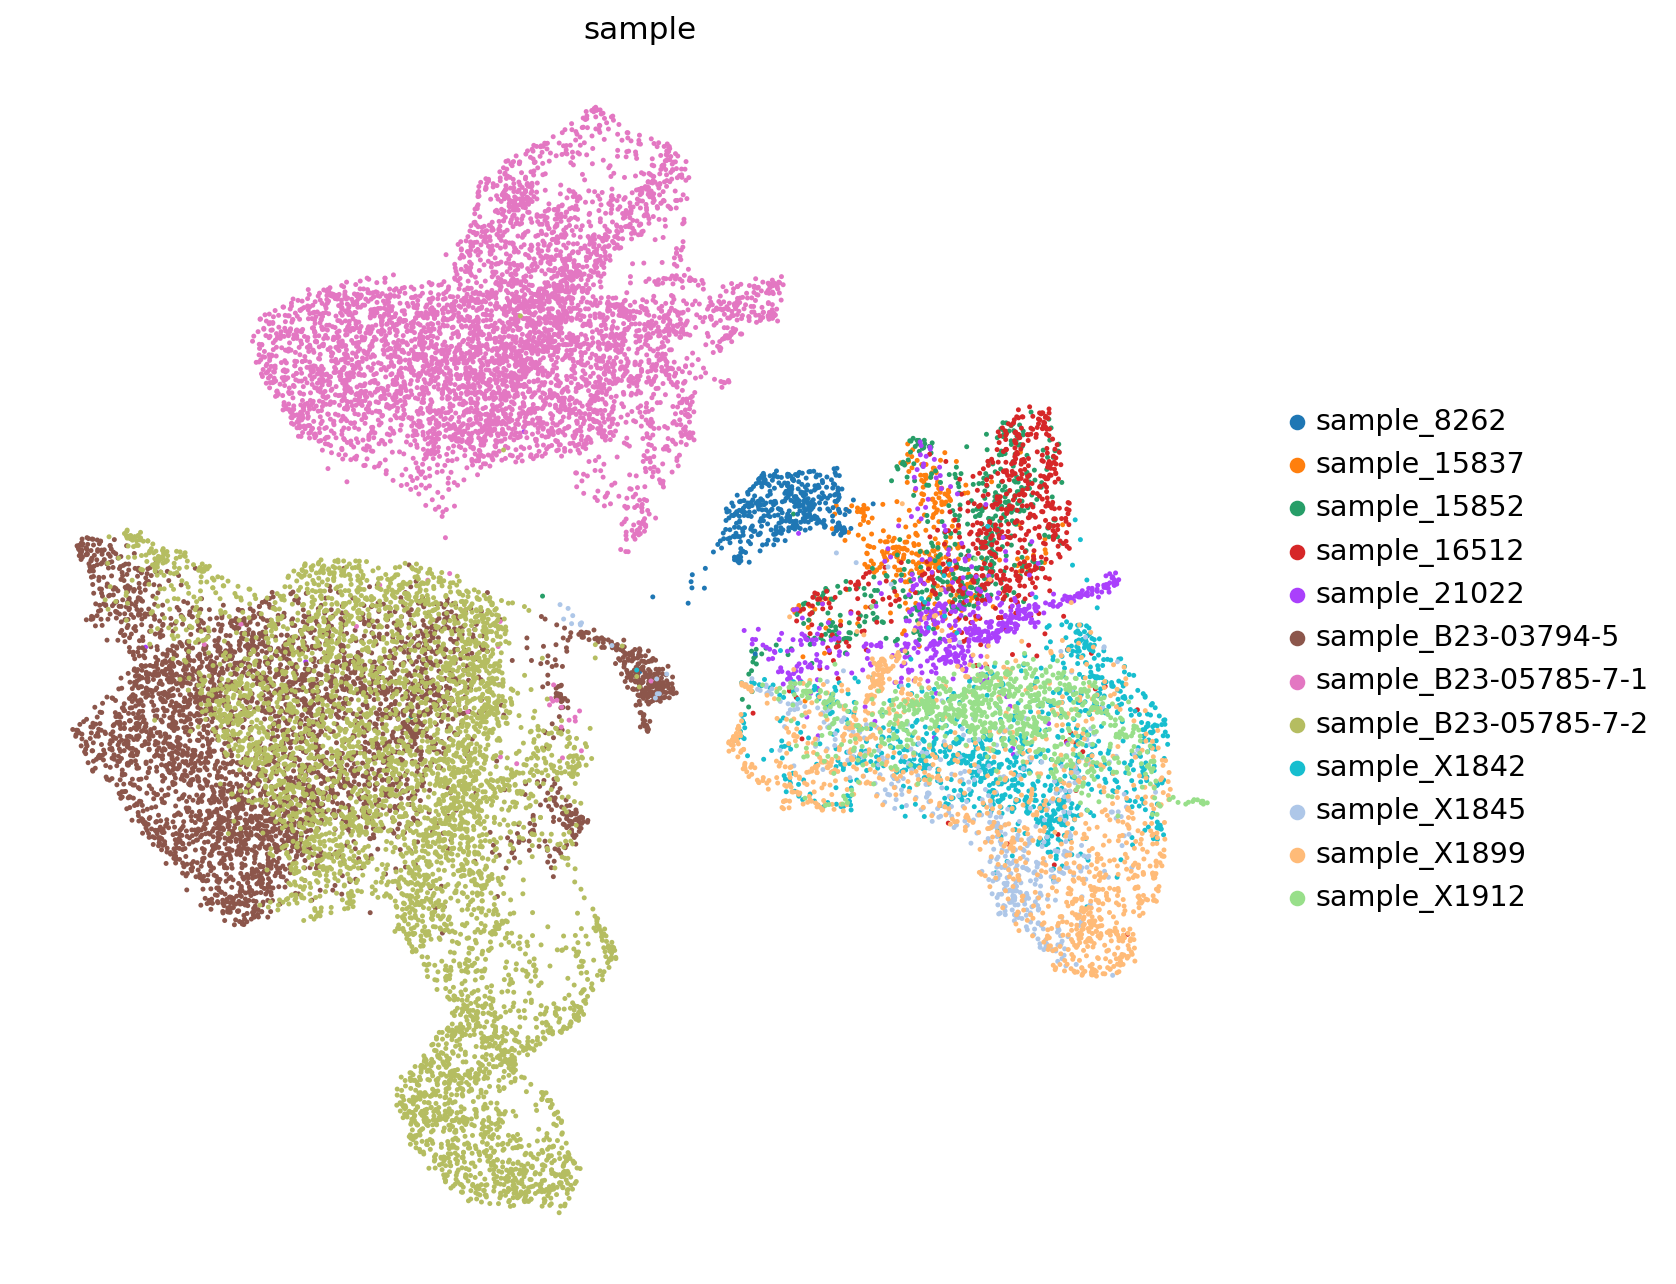

In [25]:
sc.set_figure_params(figsize=(10, 10))
sc.pl.umap(adata, color="sample", size=20, frameon=False)

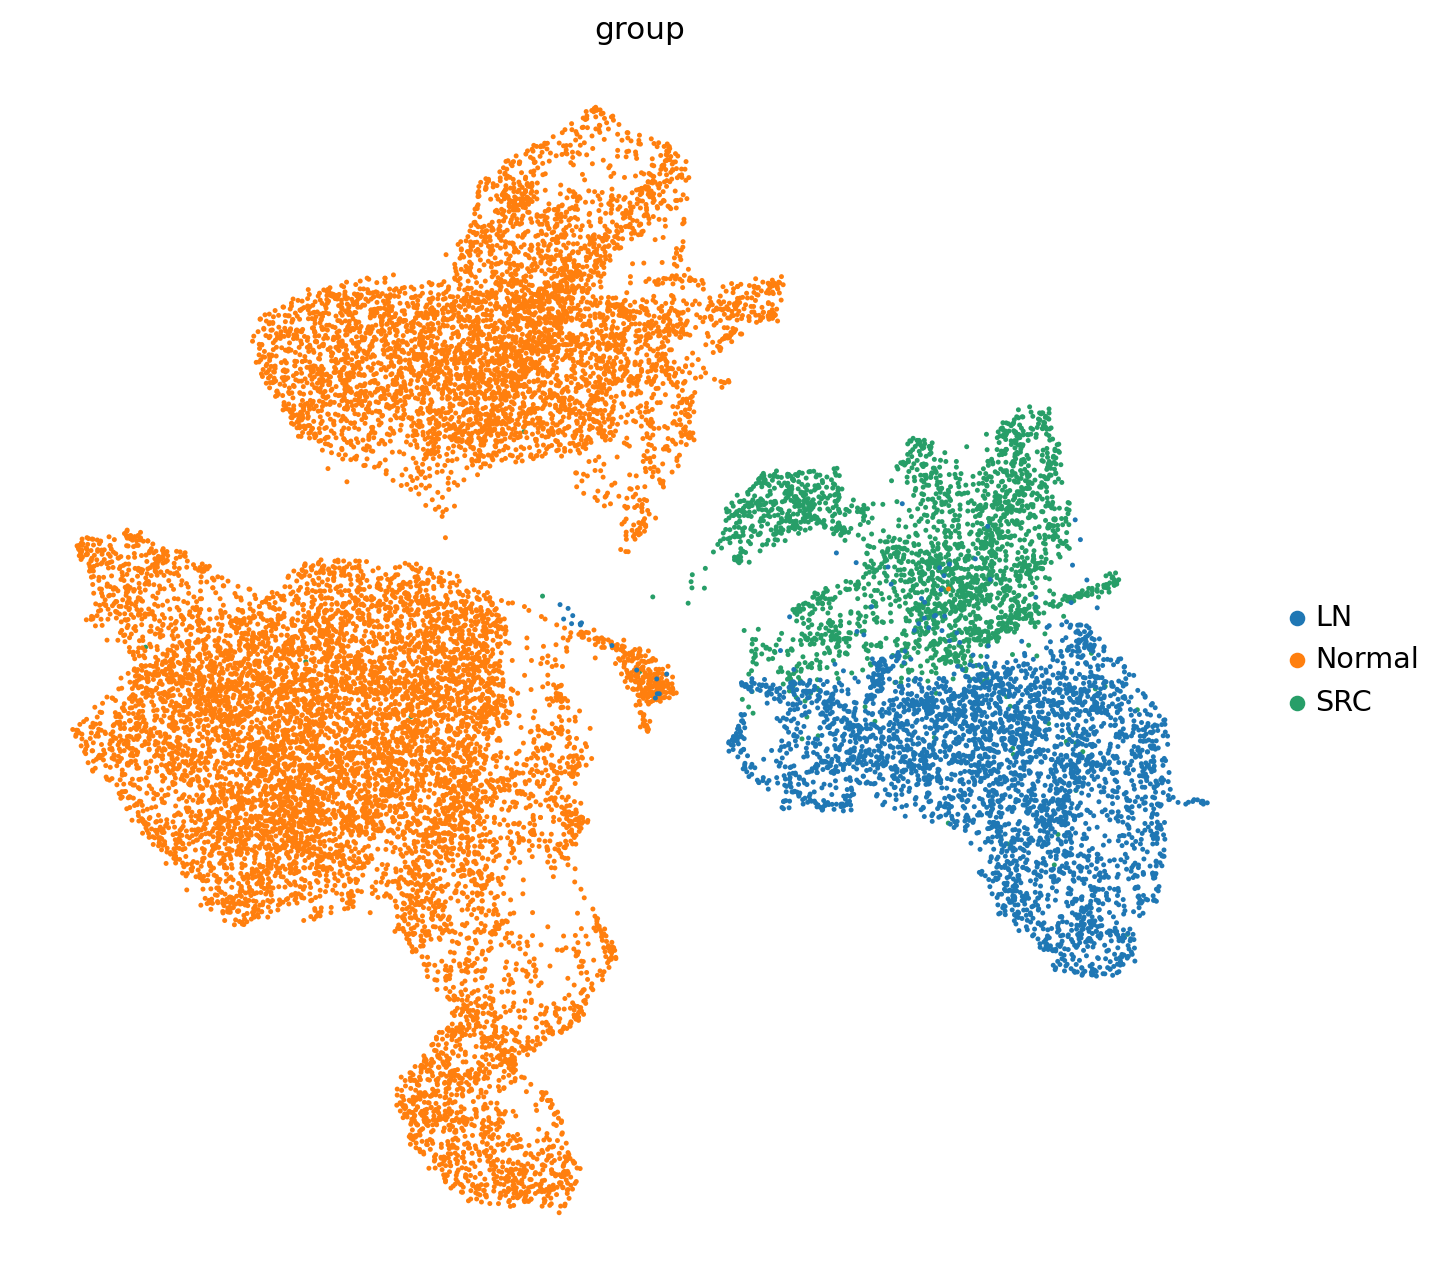

In [26]:
sc.set_figure_params(figsize=(10, 10))
sc.pl.umap(adata, color="group", size=20, frameon=False)

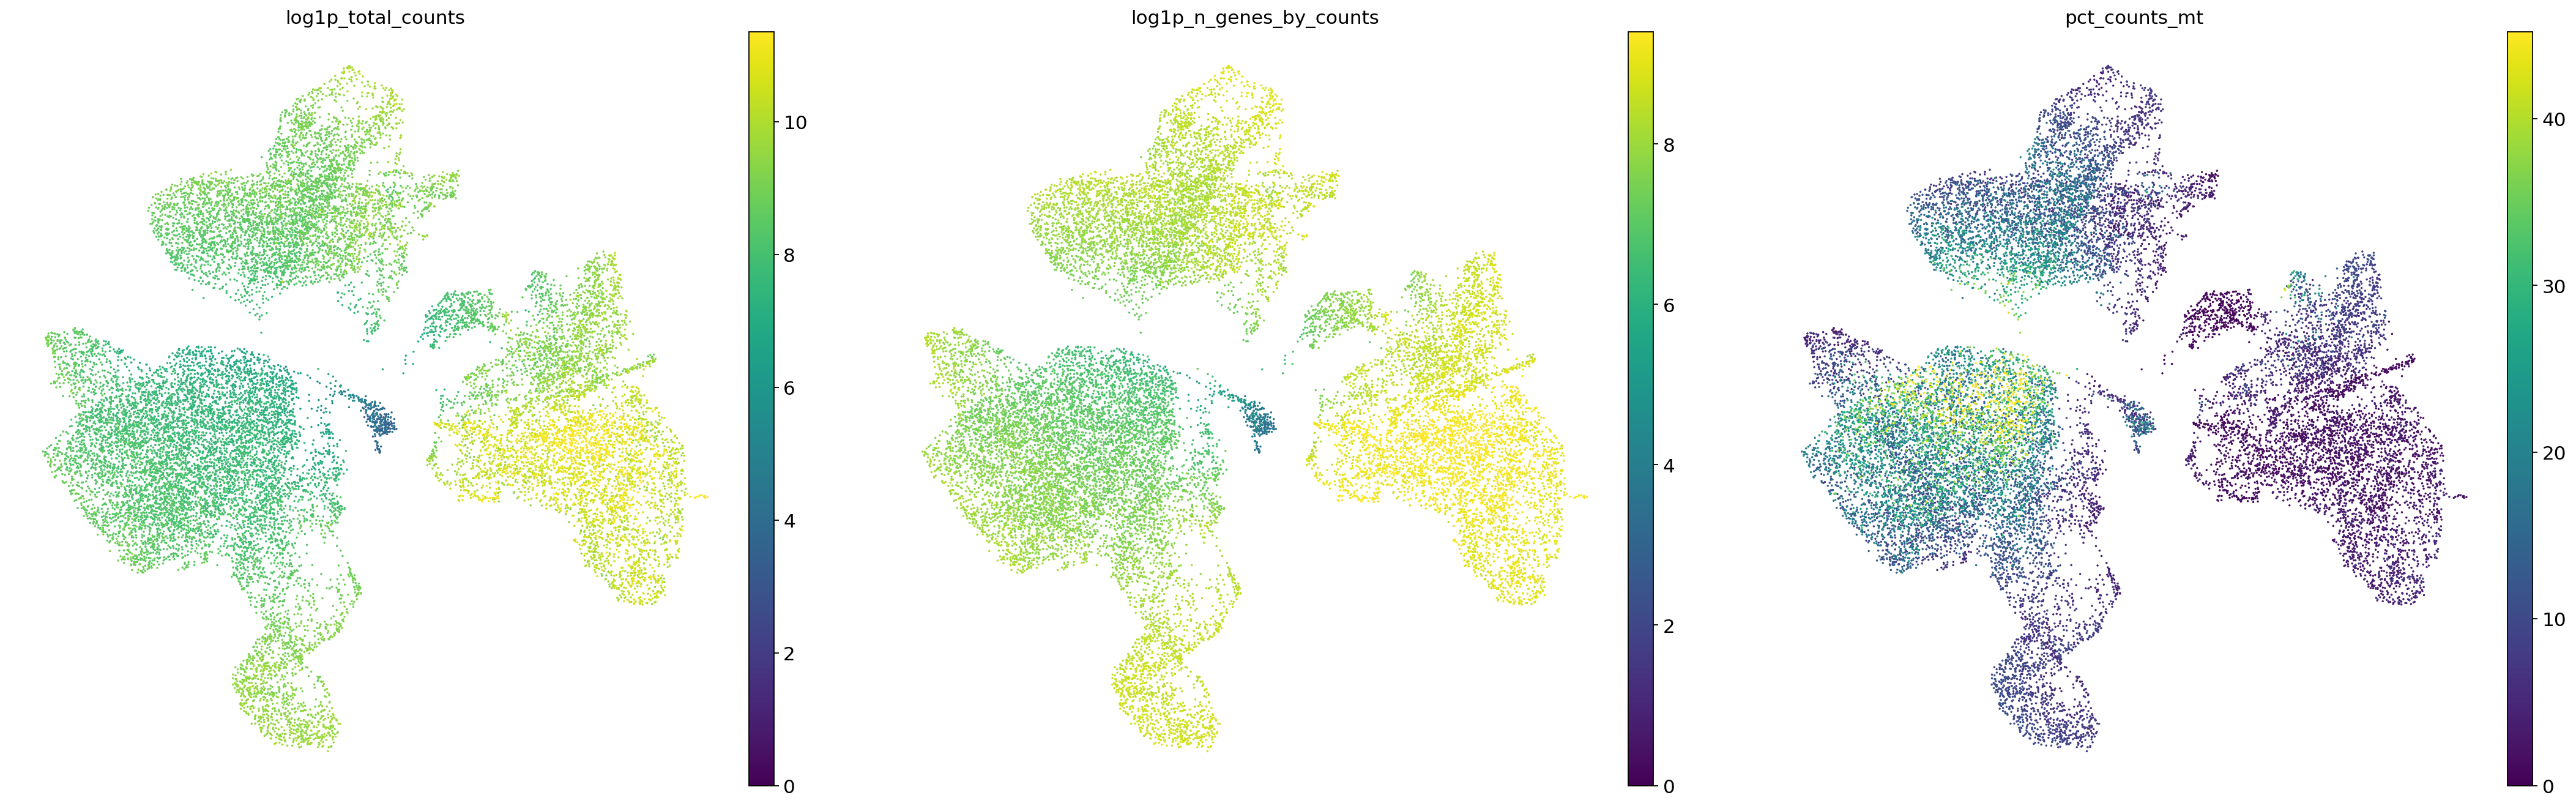

In [27]:
sc.pl.umap(adata, color=['log1p_total_counts', 'log1p_n_genes_by_counts', 'pct_counts_mt'], 
           size=10, frameon=False, cmap='viridis', vmin=0, vmax='p99')

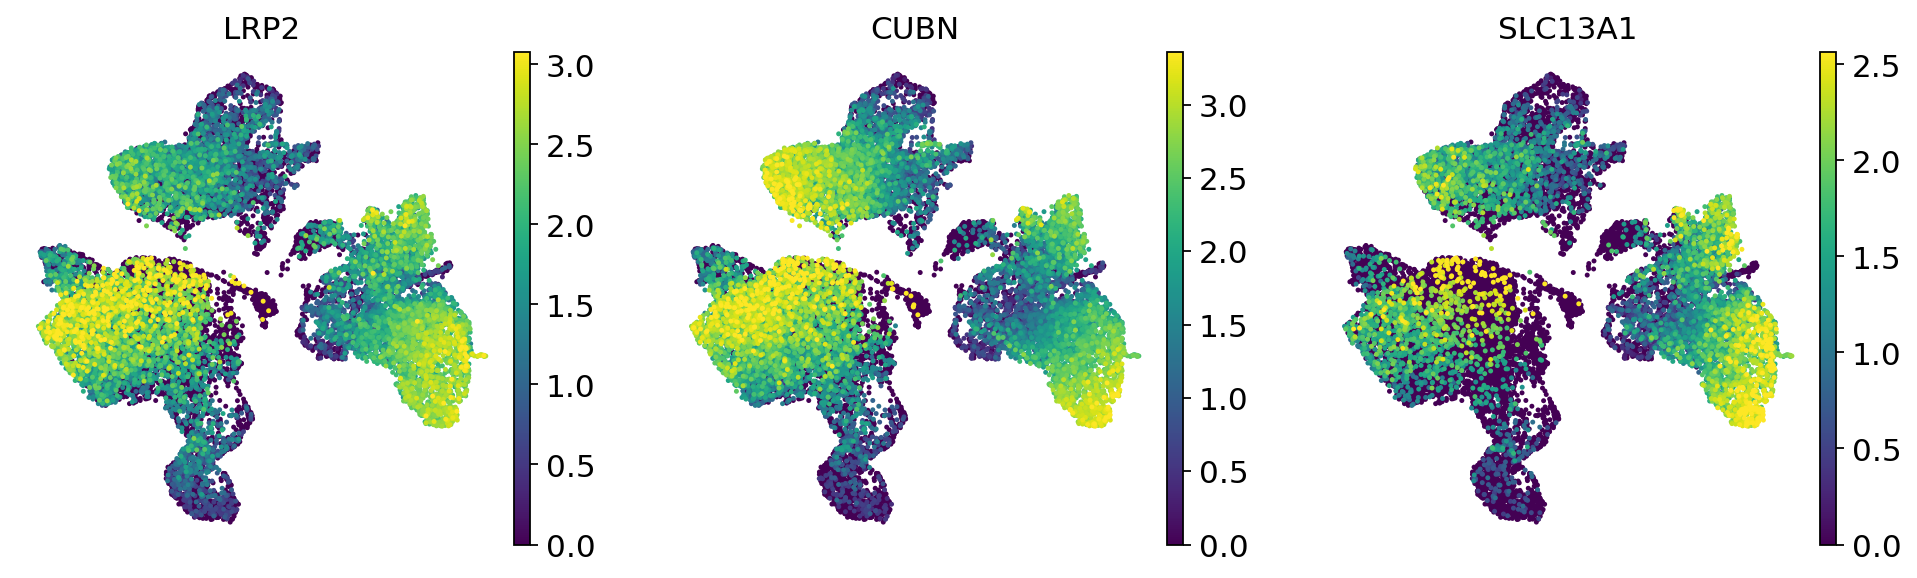

In [28]:
sc.settings.set_figure_params(figsize=(4, 4))

sc.pl.umap(adata, color=['LRP2', 'CUBN', 'SLC13A1'], size=20, frameon=False, cmap='viridis', vmin=0, vmax='p99')

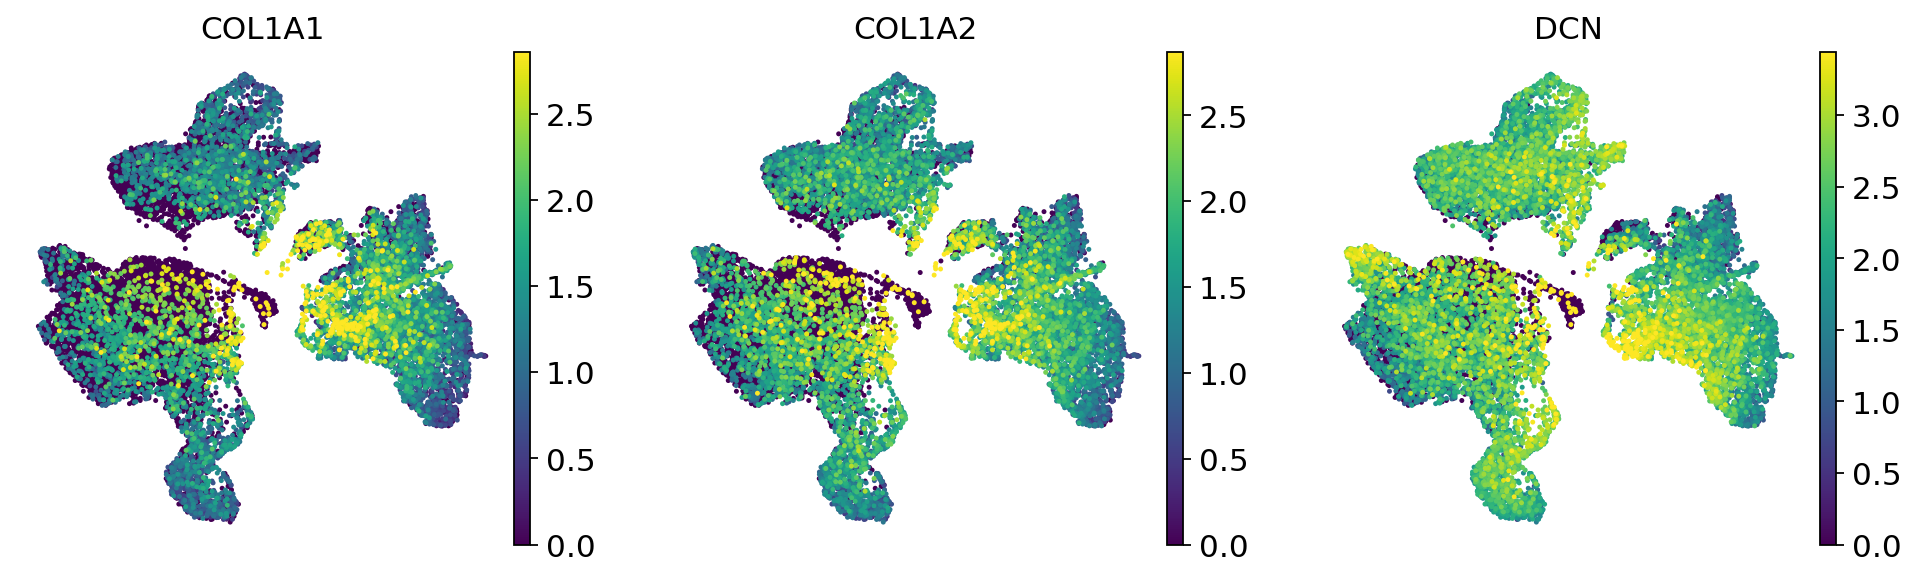

In [29]:
sc.pl.umap(adata, color=['COL1A1', 'COL1A2', 'DCN'], size=20, frameon=False, cmap='viridis', vmin=0, vmax='p99')

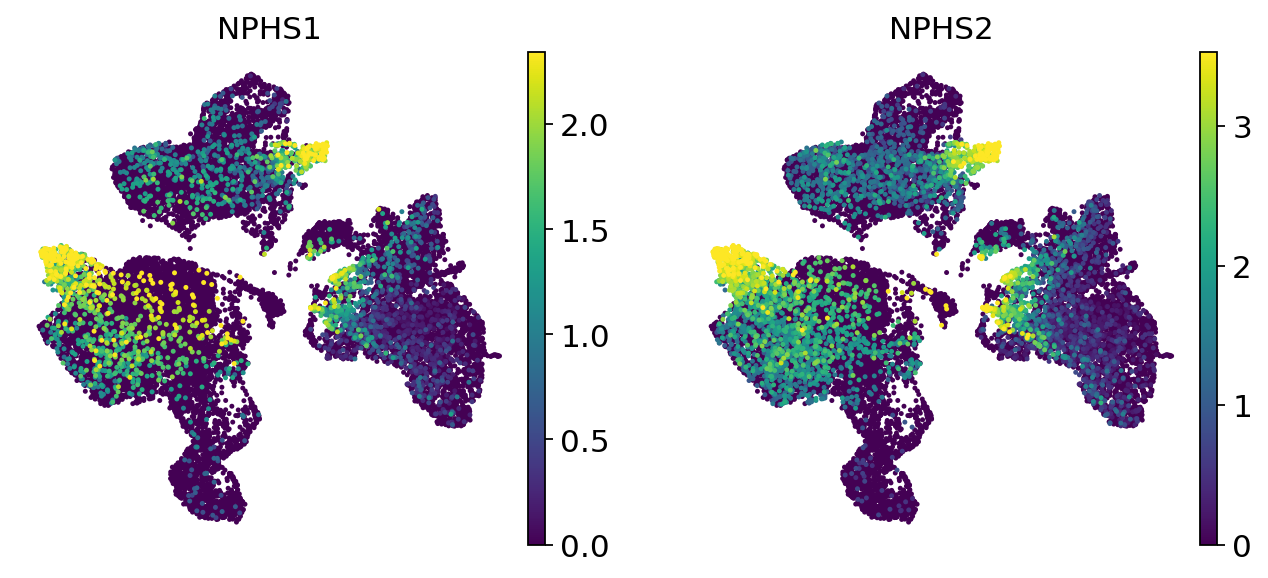

In [30]:
sc.pl.umap(adata, color=['NPHS1', 'NPHS2'], size=20, frameon=False, cmap='viridis', vmin=0, vmax='p99')

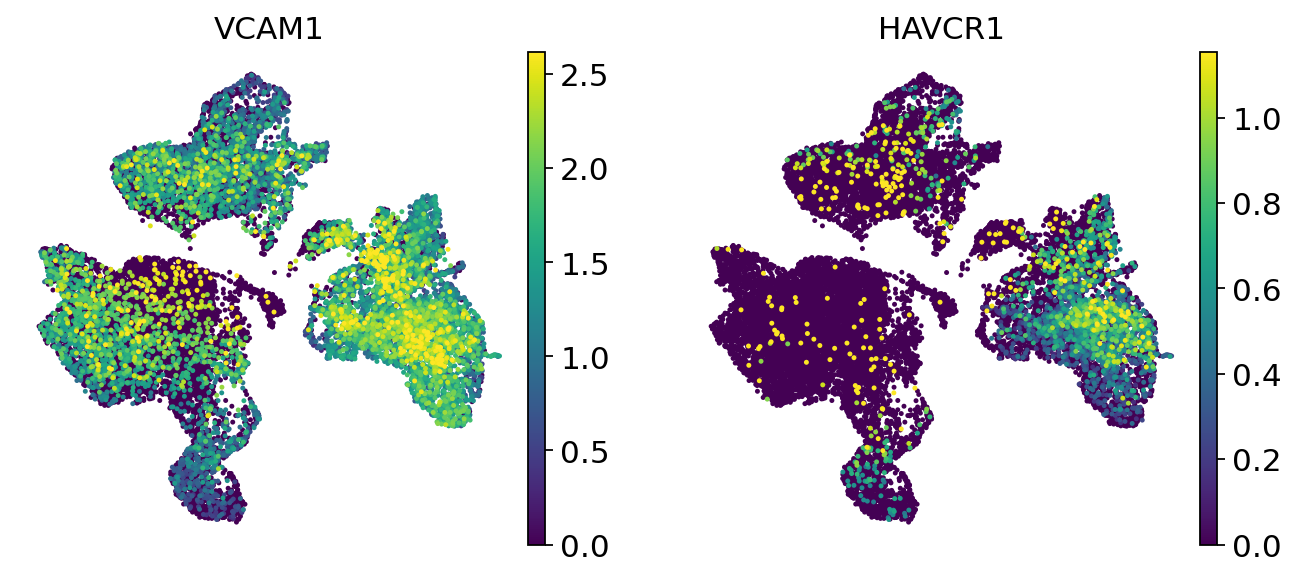

In [31]:
sc.pl.umap(adata, color=['VCAM1', 'HAVCR1'], size=20, frameon=False, cmap='viridis', vmin=0, vmax='p99')

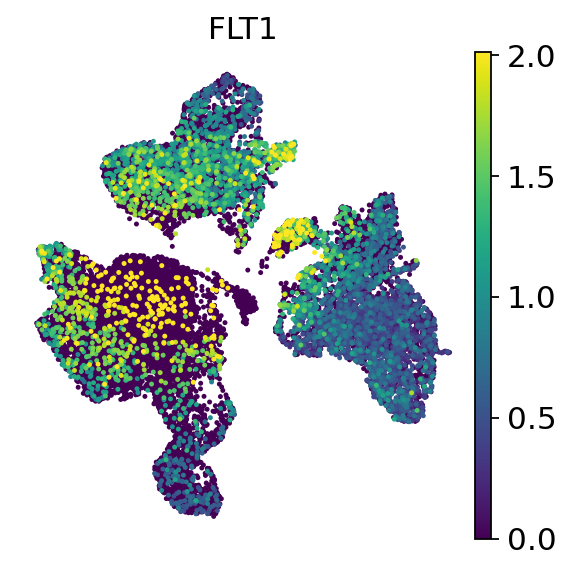

In [32]:
sc.pl.umap(adata, color=['FLT1'], size=20, frameon=False, cmap='viridis', vmin=0, vmax='p99')